**IMPORT PACKAGES**

In [ ]:
!pip install https://github.com/scikit-learn-contrib/scikit-learn-extra/archive/master.zip

     - 740.3 kB 2.0 MB/s 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import datetime as dt
from sklearn_extra.cluster import KMedoids

**IMPORT DATA**

In [ ]:
#membaca data
import pandas as pd
from google.colab import files
contoh = pd.read_excel ('PENJUALAN AMV BULAN JULI 2024.xlsx')
contoh.head()

,No. Pesanan,Status Pesanan,Status Pembatalan/ Pengembalian,No. Resi,Opsi Pengiriman,Antar ke counter/ pick-up,Pesanan Harus Dikirimkan Sebelum (Menghindari keterlambatan),Waktu Pengiriman Diatur,Waktu Pesanan Dibuat,Waktu Pembayaran Dilakukan,...,Perkiraan Ongkos Kirim,Catatan dari Pembeli,Catatan,Username (Pembeli),Nama Penerima,No. Telepon,Alamat Pengiriman,Kota/Kabupaten,Provinsi,Waktu Pesanan Selesai
0,240701FVK4ND3G,Sedang Dikirim,NaN,SPXID041244476297,Hemat-SPX Hemat,Pickup,2024-07-02 23:59,2024-07-02 14:23,2024-07-01 22:15,2024-07-01 22:15,...,65.0,NaN,NaN,mieeeajaaa,H***i,******14,"Jalan Manunggal Bhakti, RT.11, Manunggal Bhakt...",KAB. NUNUKAN,KALIMANTAN UTARA,NaN
1,2407119U9V6F94,Sedang Dikirim,NaN,SPXID045377573637,Hemat-SPX Hemat,Pickup,2024-07-11 23:59,2024-07-11 13:58,2024-07-11 02:22,2024-07-11 02:22,...,43.1,NaN,NaN,rizkydavid345,R***y,******85,"Agape gria (Blok f7no6), KAB. MINAHASA UTARA, ...",KAB. MINAHASA UTARA,SULAWESI UTARA,NaN
2,240712DEUS2E3U,Sedang Dikirim,NaN,SPXID047198446007,Hemat-SPX Hemat,Pickup,2024-07-15 23:59,2024-07-12 14:52,2024-07-12 12:50,2024-07-12 12:50,...,40.5,NaN,NaN,7fe2c01fjd,Z******r,******54,"Gereja Gmim Eklesia Pandu, Jalan Kelurahan Pan...",KOTA MANADO,SULAWESI UTARA,NaN
3,240713GNBE1ED1,Sedang Dikirim,NaN,SPXID040737687127,Hemat-SPX Hemat,Pickup,2024-07-15 23:59,2024-07-15 19:13,2024-07-13 19:24,2024-07-13 19:24,...,43.1,NaN,NaN,o71wsuunew,D******g,******73,"Kompleks Gereja Kanaan, Jalan Mercu Buana Ului...",KOTA TOMOHON,SULAWESI UTARA,NaN
4,240715N8SBDS51,Sedang Dikirim,NaN,SPXID042196664437,Hemat-SPX Hemat,Pickup,2024-07-16 23:59,2024-07-15 19:14,2024-07-15 15:23,2024-07-15 15:23,...,38.5,NaN,NaN,abriantoliante,A******e,******66,"Jalan Uyang Lahai No. 30, RT.6, Desa Miau Baru...",KAB. KUTAI TIMUR,KALIMANTAN TIMUR,NaN


In [ ]:
contoh.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170 entries, 0 to 169
Data columns (total 48 columns):
 #   Column                                                        Non-Null Count  Dtype  
---  ------                                                        --------------  -----  
 0   No. Pesanan                                                   170 non-null    object 
 1   Status Pesanan                                                170 non-null    object 
 2   Status Pembatalan/ Pengembalian                               0 non-null      float64
 3   No. Resi                                                      170 non-null    object 
 4   Opsi Pengiriman                                               170 non-null    object 
 5   Antar ke counter/ pick-up                                     170 non-null    object 
 6   Pesanan Harus Dikirimkan Sebelum (Menghindari keterlambatan)  170 non-null    object 
 7   Waktu Pengiriman Diatur                                       170 non-n

**PRE-PROCESSING DATA**

In [ ]:
#1. Ambil kolom yang diperlukan
contoh=contoh[['No. Pesanan','Waktu Pesanan Dibuat','Waktu Pembayaran Dilakukan',
               'Nama Produk','Harga Awal','Harga Setelah Diskon','Diskon Dari Penjual',
              'Jumlah Produk di Pesan','Total Pembayaran','Username (Pembeli)','Kota/Kabupaten']]
print(contoh.shape)

(170, 11)


In [ ]:
#2. Cek missing value
if contoh.isnull().any().any():
    contoh.dropna(inplace=True)
    print("Missing value telah dihapus")
else:
    print("Tidak terdapat missing value")

Tidak terdapat missing value


In [ ]:
#3. Lihat deskripsi variabel
contoh.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170 entries, 0 to 169
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   No. Pesanan                 170 non-null    object 
 1   Waktu Pesanan Dibuat        170 non-null    object 
 2   Waktu Pembayaran Dilakukan  170 non-null    object 
 3   Nama Produk                 170 non-null    object 
 4   Harga Awal                  170 non-null    float64
 5   Harga Setelah Diskon        170 non-null    float64
 6   Diskon Dari Penjual         170 non-null    float64
 7   Jumlah Produk di Pesan      170 non-null    int64  
 8   Total Pembayaran            170 non-null    float64
 9   Username (Pembeli)          170 non-null    object 
 10  Kota/Kabupaten              170 non-null    object 
dtypes: float64(4), int64(1), object(6)
memory usage: 14.7+ KB


In [ ]:
contoh.head()

,No. Pesanan,Waktu Pesanan Dibuat,Waktu Pembayaran Dilakukan,Nama Produk,Harga Awal,Harga Setelah Diskon,Diskon Dari Penjual,Jumlah Produk di Pesan,Total Pembayaran,Username (Pembeli),Kota/Kabupaten
0,240701FVK4ND3G,2024-07-01 22:15,2024-07-01 22:15,Pelindung Jok Motor Amv Premium Vario Beat Mio...,100.0,41.9,58.1,1,81.900,mieeeajaaa,KAB. NUNUKAN
1,2407119U9V6F94,2024-07-11 02:22,2024-07-11 02:22,Sarung Jok Motor Amv Premium Nmax Aerox Vespa ...,120.0,69.6,50.4,1,89.220,rizkydavid345,KAB. MINAHASA UTARA
2,240712DEUS2E3U,2024-07-12 12:50,2024-07-12 12:50,Sarung Jok Motor Amv Premium Nmax Aerox Vespa ...,120.0,69.6,50.4,1,93.704,7fe2c01fjd,KOTA MANADO
3,240713GNBE1ED1,2024-07-13 19:24,2024-07-13 19:24,Sarung Jok Motor Amv Motif Premium Nmax Aerox ...,120.0,73.2,46.8,1,78.980,o71wsuunew,KOTA TOMOHON
4,240715N8SBDS51,2024-07-15 15:23,2024-07-15 15:23,Sarung Jok Motor Vespa Nmax Aerox Pcx Vario Be...,100.0,42.0,58.0,1,63.920,abriantoliante,KAB. KUTAI TIMUR


In [ ]:
#4. Ubah tipe data untuk variabel waktu pembayaran dilakukan
from datetime import datetime
contoh['Waktu Pembayaran Dilakukan'] = pd.to_datetime(contoh['Waktu Pembayaran Dilakukan'])
contoh['Waktu Pembayaran Dilakukan'] = pd.to_datetime(contoh['Waktu Pembayaran Dilakukan']).dt.date
contoh['Waktu Pesanan Dibuat'] = pd.to_datetime(contoh['Waktu Pesanan Dibuat'])
contoh['Waktu Pesanan Dibuat'] = pd.to_datetime(contoh['Waktu Pesanan Dibuat']).dt.date
contoh.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170 entries, 0 to 169
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   No. Pesanan                 170 non-null    object 
 1   Waktu Pesanan Dibuat        170 non-null    object 
 2   Waktu Pembayaran Dilakukan  170 non-null    object 
 3   Nama Produk                 170 non-null    object 
 4   Harga Awal                  170 non-null    float64
 5   Harga Setelah Diskon        170 non-null    float64
 6   Diskon Dari Penjual         170 non-null    float64
 7   Jumlah Produk di Pesan      170 non-null    int64  
 8   Total Pembayaran            170 non-null    float64
 9   Username (Pembeli)          170 non-null    object 
 10  Kota/Kabupaten              170 non-null    object 
dtypes: float64(4), int64(1), object(6)
memory usage: 14.7+ KB


In [ ]:
#5. Varibel numerik diubah menjadi ribuan
contoh['Harga Awal']= contoh['Harga Awal']*1000
contoh['Harga Setelah Diskon']= contoh['Harga Setelah Diskon']*1000
contoh['Diskon Dari Penjual']= contoh['Diskon Dari Penjual']*1000
contoh['Total Pembayaran']= contoh['Total Pembayaran']*1000
contoh.head()

,No. Pesanan,Waktu Pesanan Dibuat,Waktu Pembayaran Dilakukan,Nama Produk,Harga Awal,Harga Setelah Diskon,Diskon Dari Penjual,Jumlah Produk di Pesan,Total Pembayaran,Username (Pembeli),Kota/Kabupaten
0,240701FVK4ND3G,2024-07-01,2024-07-01,Pelindung Jok Motor Amv Premium Vario Beat Mio...,100000.0,41900.0,58100.0,1,81900.0,mieeeajaaa,KAB. NUNUKAN
1,2407119U9V6F94,2024-07-11,2024-07-11,Sarung Jok Motor Amv Premium Nmax Aerox Vespa ...,120000.0,69600.0,50400.0,1,89220.0,rizkydavid345,KAB. MINAHASA UTARA
2,240712DEUS2E3U,2024-07-12,2024-07-12,Sarung Jok Motor Amv Premium Nmax Aerox Vespa ...,120000.0,69600.0,50400.0,1,93704.0,7fe2c01fjd,KOTA MANADO
3,240713GNBE1ED1,2024-07-13,2024-07-13,Sarung Jok Motor Amv Motif Premium Nmax Aerox ...,120000.0,73200.0,46800.0,1,78980.0,o71wsuunew,KOTA TOMOHON
4,240715N8SBDS51,2024-07-15,2024-07-15,Sarung Jok Motor Vespa Nmax Aerox Pcx Vario Be...,100000.0,42000.0,58000.0,1,63920.0,abriantoliante,KAB. KUTAI TIMUR


In [ ]:
#6. Ubah tipe data
contoh['Harga Awal']= contoh['Harga Awal'].astype("int64")
contoh['Harga Setelah Diskon']= contoh['Harga Setelah Diskon'].astype("int64")
contoh['Diskon Dari Penjual']= contoh['Diskon Dari Penjual'].astype("int64")
contoh['Total Pembayaran']= contoh['Total Pembayaran'].astype("int64")
contoh.head()


,No. Pesanan,Waktu Pesanan Dibuat,Waktu Pembayaran Dilakukan,Nama Produk,Harga Awal,Harga Setelah Diskon,Diskon Dari Penjual,Jumlah Produk di Pesan,Total Pembayaran,Username (Pembeli),Kota/Kabupaten
0,240701FVK4ND3G,2024-07-01,2024-07-01,Pelindung Jok Motor Amv Premium Vario Beat Mio...,100000,41900,58100,1,81900,mieeeajaaa,KAB. NUNUKAN
1,2407119U9V6F94,2024-07-11,2024-07-11,Sarung Jok Motor Amv Premium Nmax Aerox Vespa ...,120000,69600,50400,1,89220,rizkydavid345,KAB. MINAHASA UTARA
2,240712DEUS2E3U,2024-07-12,2024-07-12,Sarung Jok Motor Amv Premium Nmax Aerox Vespa ...,120000,69600,50400,1,93704,7fe2c01fjd,KOTA MANADO
3,240713GNBE1ED1,2024-07-13,2024-07-13,Sarung Jok Motor Amv Motif Premium Nmax Aerox ...,120000,73200,46800,1,78980,o71wsuunew,KOTA TOMOHON
4,240715N8SBDS51,2024-07-15,2024-07-15,Sarung Jok Motor Vespa Nmax Aerox Pcx Vario Be...,100000,42000,58000,1,63920,abriantoliante,KAB. KUTAI TIMUR


In [ ]:
#7. Cek kembali tipe data
contoh.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170 entries, 0 to 169
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   No. Pesanan                 170 non-null    object
 1   Waktu Pesanan Dibuat        170 non-null    object
 2   Waktu Pembayaran Dilakukan  170 non-null    object
 3   Nama Produk                 170 non-null    object
 4   Harga Awal                  170 non-null    int64 
 5   Harga Setelah Diskon        170 non-null    int64 
 6   Diskon Dari Penjual         170 non-null    int64 
 7   Jumlah Produk di Pesan      170 non-null    int64 
 8   Total Pembayaran            170 non-null    int64 
 9   Username (Pembeli)          170 non-null    object
 10  Kota/Kabupaten              170 non-null    object
dtypes: int64(5), object(6)
memory usage: 14.7+ KB


In [ ]:
#8. Labelling untuk variabel Kota/Kabupaten
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
contoh['kode_kota_kab'] = le.fit_transform(contoh['Kota/Kabupaten'])

In [ ]:
#9. Lihat hasil labeling kota
print(contoh.loc[:, ['Kota/Kabupaten', 'kode_kota_kab']])

             Kota/Kabupaten  kode_kota_kab
0              KAB. NUNUKAN             44
1       KAB. MINAHASA UTARA             40
2               KOTA MANADO             71
3              KOTA TOMOHON             81
4          KAB. KUTAI TIMUR             29
..                      ...            ...
165        KAB. TANAH DATAR             57
166               KOTA PALU             75
167  KAB. KUTAI KARTANEGARA             28
168        KAB. KUTAI TIMUR             29
169            KAB. BANGGAI              2

[170 rows x 2 columns]


In [ ]:
#10. Labelling untuk variabel produk
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
contoh['kode_produk'] = le.fit_transform(contoh['Nama Produk'])

In [ ]:
#11. Lihat hasil labeling produk
print(contoh.loc[:, ['Nama Produk', 'kode_produk']])

                                           Nama Produk  kode_produk
0    Pelindung Jok Motor Amv Premium Vario Beat Mio...            4
1    Sarung Jok Motor Amv Premium Nmax Aerox Vespa ...           15
2    Sarung Jok Motor Amv Premium Nmax Aerox Vespa ...           15
3    Sarung Jok Motor Amv Motif Premium Nmax Aerox ...           12
4    Sarung Jok Motor Vespa Nmax Aerox Pcx Vario Be...           19
..                                                 ...          ...
165  Sarung Motor Nmax Aerox Lexi Vespa Pcx Adv Var...           23
166  Sarung Jok Motor Amv Premium Nmax Aerox Vespa ...           15
167  Pelindung Jok Motor Amv Premium Vario Beat Mio...            4
168  Sarung Jok Motor Amv Motif Premium Nmax Aerox ...           12
169  Sarung Jok Motor Amv Premium Nmax Aerox Vespa ...           15

[170 rows x 2 columns]


In [ ]:
#12. Download data hasil transformasi
contoh.to_excel('hasil transformasi.xlsx', index=False)

**ANALISIS RFM**

In [ ]:
#Mencari nilai recency
import datetime
contoh['Waktu Pembayaran Dilakukan'] = pd.to_datetime(contoh['Waktu Pembayaran Dilakukan'])
tanggal_acuan = datetime.date(2024, 8, 18)
contoh['Recency'] = contoh['Waktu Pembayaran Dilakukan'].apply(lambda x: (tanggal_acuan - x.date()).days)

In [ ]:
#Mencari nilai frekuensi
frequency_data = contoh.groupby('Username (Pembeli)')['No. Pesanan'].count().reset_index()
frequency_data.rename(columns= {'No. Pesanan': 'Frequency'}, inplace = True)
contoh = contoh.merge(frequency_data, on = 'Username (Pembeli)')

In [ ]:
#Mencari nilai monetary
monetary_data = contoh.groupby('Username (Pembeli)')['Total Pembayaran'].sum().reset_index()
monetary_data.rename(columns={'Total Pembayaran': 'Monetary'}, inplace = True)
contoh = contoh.merge(monetary_data, on = 'Username (Pembeli)')

In [ ]:
#Menampilkan hasil RFM
contoh.head()

,No. Pesanan,Waktu Pesanan Dibuat,Waktu Pembayaran Dilakukan,Nama Produk,Harga Awal,Harga Setelah Diskon,Diskon Dari Penjual,Jumlah Produk di Pesan,Total Pembayaran,Username (Pembeli),Kota/Kabupaten,kode_kota_kab,kode_produk,Recency,Frequency,Monetary
0,240701FVK4ND3G,2024-07-01,2024-07-01,Pelindung Jok Motor Amv Premium Vario Beat Mio...,100000,41900,58100,1,81900,mieeeajaaa,KAB. NUNUKAN,44,4,48,1,81900
1,2407119U9V6F94,2024-07-11,2024-07-11,Sarung Jok Motor Amv Premium Nmax Aerox Vespa ...,120000,69600,50400,1,89220,rizkydavid345,KAB. MINAHASA UTARA,40,15,38,1,89220
2,240712DEUS2E3U,2024-07-12,2024-07-12,Sarung Jok Motor Amv Premium Nmax Aerox Vespa ...,120000,69600,50400,1,93704,7fe2c01fjd,KOTA MANADO,71,15,37,1,93704
3,240713GNBE1ED1,2024-07-13,2024-07-13,Sarung Jok Motor Amv Motif Premium Nmax Aerox ...,120000,73200,46800,1,78980,o71wsuunew,KOTA TOMOHON,81,12,36,1,78980
4,240715N8SBDS51,2024-07-15,2024-07-15,Sarung Jok Motor Vespa Nmax Aerox Pcx Vario Be...,100000,42000,58000,1,63920,abriantoliante,KAB. KUTAI TIMUR,29,19,34,1,63920


**ANALISIS K-MEDOIDS**

In [ ]:
#Ambil variabel yang akan digunakan untuk analisis cluster K-Medoids
analisis = contoh[['Recency','Frequency', 'Monetary','kode_kota_kab', 'kode_produk',
                   'Harga Awal', 'Harga Setelah Diskon','Diskon Dari Penjual',
                   'Jumlah Produk di Pesan']]

In [ ]:
#lihat data analisis
analisis.head()

,Recency,Frequency,Monetary,kode_kota_kab,kode_produk,Harga Awal,Harga Setelah Diskon,Diskon Dari Penjual,Jumlah Produk di Pesan
0,48,1,81900,44,4,100000,41900,58100,1
1,38,1,89220,40,15,120000,69600,50400,1
2,37,1,93704,71,15,120000,69600,50400,1
3,36,1,78980,81,12,120000,73200,46800,1
4,34,1,63920,29,19,100000,42000,58000,1


In [ ]:
#Normalisasi menggunakan min-max
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
analisisfix = scaler.fit_transform(analisis)

In [ ]:
#Tampilkan hasil normalisasi
analisisfix = pd.DataFrame(analisisfix)
analisisfix.head()

,0,1,2,3,4,5,6,7,8
0,1.000000,0.0,0.052350,0.543210,0.16,0.809524,0.480863,0.196037,0.0
1,0.666667,0.0,0.058620,0.493827,0.60,1.000000,0.866388,0.166116,0.0
2,0.633333,0.0,0.062462,0.876543,0.60,1.000000,0.866388,0.166116,0.0
3,0.600000,0.0,0.049848,1.000000,0.48,1.000000,0.916493,0.152127,0.0
4,0.533333,0.0,0.036947,0.358025,0.76,0.809524,0.482255,0.195648,0.0


In [ ]:
#Menentukan banyaknya cluster menggunakan metode elbow
np.random.seed(42)
distortions = []
for k in range(2, 11):  # try different values of k
    kmedoids = KMedoids(n_clusters=k, random_state=42)
    kmedoids.fit(analisisfix)
    distortions.append(kmedoids.inertia_)

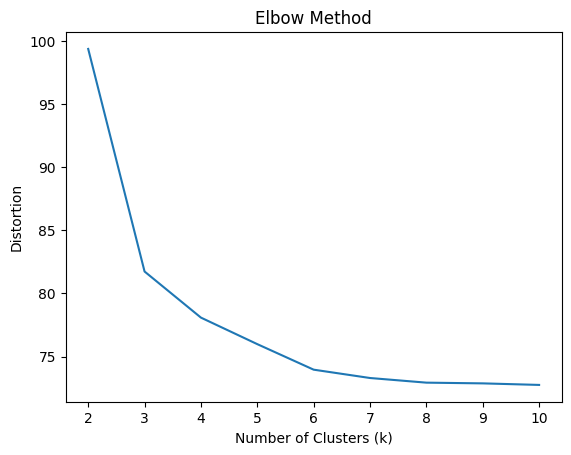

In [ ]:
#Visualisasi metode elbow
plt.plot(range(2, 11), distortions)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Distortion')
plt.title('Elbow Method')
plt.show()

In [ ]:
#Validasi cluster menggunakan DBI
from sklearn.metrics import davies_bouldin_score
np.random.seed(42)
dbi_scores = []
for k in range(2, 10):  # try different values of k
    kmedoids = KMedoids(n_clusters=k, random_state=42)
    kmedoids.fit(analisisfix)
    labels = kmedoids.labels_
    dbi_scores.append(davies_bouldin_score(analisisfix, labels))
#skor DBI
print("DBI scores:")
for k, score in enumerate(dbi_scores, start=2):
    print(f"k={k}: {score:.3f}")

DBI scores:
k=2: 1.458
k=3: 1.120
k=4: 1.450
k=5: 1.475
k=6: 1.420
k=7: 1.731
k=8: 1.963
k=9: 1.732


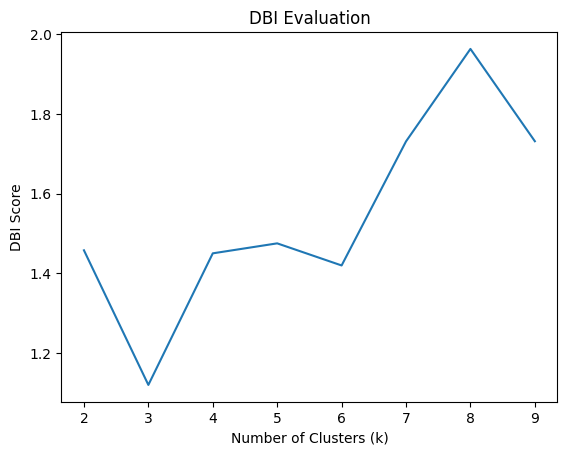

In [ ]:
#Visualisasi DBI
plt.plot(range(2, 10), dbi_scores)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('DBI Score')
plt.title('DBI Evaluation')
plt.show()

In [ ]:
#Validasi cluster dengan Silhouette Coefficient
from sklearn.metrics import silhouette_score
np.random.seed(42)
silhouette_scores = []
for k in range(2, 10):  # try different values of k
    kmedoids = KMedoids(n_clusters=k, random_state=42)
    kmedoids.fit(analisisfix)
    labels = kmedoids.labels_
    silhouette_scores.append(silhouette_score(analisisfix, labels))
#nilai SC tiap cluster
print("Silhouette scores:")
for k, score in enumerate(silhouette_scores, start=2):
    print(f"k={k}: {score:.3f}")

Silhouette scores:
k=2: 0.281
k=3: 0.352
k=4: 0.287
k=5: 0.250
k=6: 0.205
k=7: 0.163
k=8: 0.135
k=9: 0.084


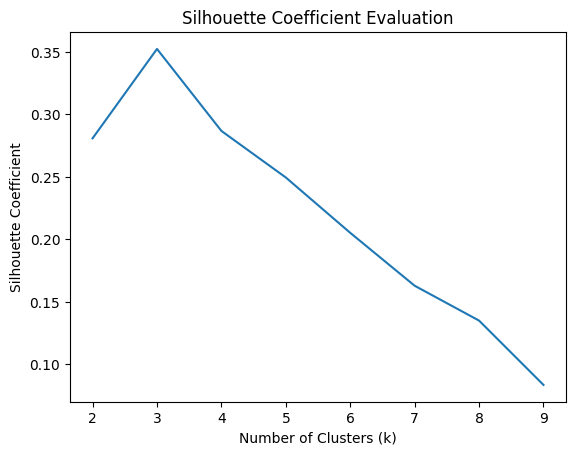

In [ ]:
#Visualisasi silhouette coefficient
plt.plot(range(2, 10), silhouette_scores)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Coefficient')
plt.title('Silhouette Coefficient Evaluation')
plt.show()

In [ ]:
#Menampilkan nilai medoids
np.random.seed(42)
kmedoids = KMedoids(n_clusters=3, init='k-medoids++', max_iter=1000, random_state=42)
kmedoids.fit(analisisfix)
print(kmedoids.cluster_centers_)

[[0.03333333 0.75       0.76391625 0.50617284 0.92       0.57142857
  0.56437022 0.07557801 0.6       ]
 [0.03333333 0.         0.03217058 0.50617284 0.92       0.57142857
  0.56437022 0.07557801 0.        ]
 [0.16666667 0.         0.08826392 0.49382716 0.48       1.
  0.94154489 0.14513309 0.        ]]


In [ ]:
#Menampilkan hasil cluster
labels=kmedoids.labels_
#Gabungkan cluster kedalam dataset
contoh['cluster']=kmedoids.labels_
contoh.head()

,No. Pesanan,Waktu Pesanan Dibuat,Waktu Pembayaran Dilakukan,Nama Produk,Harga Awal,Harga Setelah Diskon,Diskon Dari Penjual,Jumlah Produk di Pesan,Total Pembayaran,Username (Pembeli),Kota/Kabupaten,kode_kota_kab,kode_produk,Recency,Frequency,Monetary,cluster
0,240701FVK4ND3G,2024-07-01,2024-07-01,Pelindung Jok Motor Amv Premium Vario Beat Mio...,100000,41900,58100,1,81900,mieeeajaaa,KAB. NUNUKAN,44,4,48,1,81900,2
1,2407119U9V6F94,2024-07-11,2024-07-11,Sarung Jok Motor Amv Premium Nmax Aerox Vespa ...,120000,69600,50400,1,89220,rizkydavid345,KAB. MINAHASA UTARA,40,15,38,1,89220,2
2,240712DEUS2E3U,2024-07-12,2024-07-12,Sarung Jok Motor Amv Premium Nmax Aerox Vespa ...,120000,69600,50400,1,93704,7fe2c01fjd,KOTA MANADO,71,15,37,1,93704,2
3,240713GNBE1ED1,2024-07-13,2024-07-13,Sarung Jok Motor Amv Motif Premium Nmax Aerox ...,120000,73200,46800,1,78980,o71wsuunew,KOTA TOMOHON,81,12,36,1,78980,2
4,240715N8SBDS51,2024-07-15,2024-07-15,Sarung Jok Motor Vespa Nmax Aerox Pcx Vario Be...,100000,42000,58000,1,63920,abriantoliante,KAB. KUTAI TIMUR,29,19,34,1,63920,1


In [ ]:
#Jumlah masing-masing pelanggan tiap cluster
contoh['cluster'].value_counts()

,count
cluster,
2,74
1,68
0,28


In [ ]:
#Download hasl clustering
contoh.to_excel('hasil cluster fix per 18 agt.xlsx', index=False)